In [ ]:
import subprocess
from pathlib import Path

repo = Path("/content/cleanrl")
commit = "fe8d8a03c41a7ef5b523e2e354bd01c363e786bb"
repo.mkdir(parents=True, exist_ok=True)

def git(*args):
    subprocess.run(["git", "-C", str(repo), *args], check=True)

git("init", "-q")
git("fetch", "--depth=1", "https://github.com/vwxyzjn/cleanrl.git", commit)
git("checkout", "--detach", "FETCH_HEAD")

assert (repo / "cleanrl" / "ppo.py").is_file()
print("STEP 1 COMPLETE: CleanRL source downloaded.")

STEP 1 COMPLETE: CleanRL source downloaded.


In [ ]:
# ============================================================
# Step 2: Install dependencies and run a short PPO pilot
# Report use: Verify the training setup before formal experiments.
# ============================================================

import subprocess
import sys
from pathlib import Path

repo = Path("/content/cleanrl")
script = repo / "cleanrl" / "ppo.py"

if not script.is_file():
    raise FileNotFoundError("Run Step 1 before running this cell.")

print("Installing training dependencies...", flush=True)
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q",
     "gymnasium", "tensorboard", "tyro"],
    check=True,
)

launcher = r"""
import runpy
import sys
import types

sys.modules["tensorboard.compat.notf"] = types.ModuleType("tensorboard.compat.notf")
script = sys.argv[1]
sys.argv = sys.argv[1:]
runpy.run_path(script, run_name="__main__")
"""

print("Starting PPO pilot...", flush=True)
subprocess.run(
    [sys.executable, "-u", "-c", launcher, str(script),
     "--env-id", "CartPole-v1",
     "--seed", "1",
     "--total-timesteps", "4096",
     "--no-cuda"],
    cwd=repo,
    check=True,
)

print("STEP 2 COMPLETE: PPO pilot finished.")

Installing training dependencies...
Starting PPO pilot...
STEP 2 COMPLETE: PPO pilot finished.


In [ ]:
# ============================================================
# Step 3: Train the clean PPO baseline with live output
# Report use: Save control-group models and training returns.
# ============================================================

import subprocess
import sys
from datetime import datetime
from pathlib import Path

repo = Path("/content/cleanrl")
script = repo / "cleanrl" / "ppo.py"

if not script.is_file():
    raise FileNotFoundError("Run Steps 1 and 2 before this cell.")

run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
baseline_dir = Path("/content/PPO_CartPole_Report/baseline_runs") / run_id

train_and_save = r"""
import runpy
import sys
import types

sys.modules["tensorboard.compat.notf"] = types.ModuleType("tensorboard.compat.notf")

script, checkpoint = sys.argv[1:3]
sys.argv = [script, *sys.argv[3:]]
result = runpy.run_path(script, run_name="__main__")

steps = result["global_step"]
if steps != 500_224:
    raise RuntimeError(f"Expected 500224 training steps, got {steps}.")

import torch

torch.save(result["agent"].state_dict(), checkpoint)
print(f"Training steps: {steps}")
print(f"Checkpoint saved: {checkpoint}")
"""

for seed in (1, 2, 3):
    seed_dir = baseline_dir / f"seed_{seed}"
    seed_dir.mkdir(parents=True)
    checkpoint = seed_dir / "model.pt"
    log_path = seed_dir / "training.log"

    command = [
        sys.executable, "-u", "-c", train_and_save,
        str(script), str(checkpoint),
        "--env-id", "CartPole-v1",
        "--seed", str(seed),
        "--total-timesteps", "500224",
        "--num-envs", "4",
        "--num-steps", "128",
        "--no-cuda",
    ]

    print(f"\nTraining seed {seed} (run {seed}/3)...", flush=True)

    with log_path.open("w", encoding="utf-8", buffering=1) as log:
        process = subprocess.Popen(
            command,
            cwd=repo,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            encoding="utf-8",
            errors="replace",
        )
        try:
            for line in process.stdout:
                log.write(line)
                print(line, end="", flush=True)
            return_code = process.wait()
        finally:
            if process.poll() is None:
                process.terminate()
                process.wait()
            process.stdout.close()

    if return_code != 0 or not checkpoint.is_file():
        raise RuntimeError(f"Training failed for seed {seed}. Log: {log_path}")

    print(f"Seed {seed} complete.", flush=True)

print("\nSTEP 3 COMPLETE: All three baseline models saved.")
print("Results folder:", baseline_dir)


Training seed 1 (run 1/3)...
/usr/local/lib/python3.13/dist-packages/tyro/_parsers.py:365: UserWarning: The field `wandb-entity` is annotated with type `<class 'str'>`, but the default value `None` has type `<class 'NoneType'>`. We'll try to handle this gracefully, but it may cause unexpected behavior.
  warnings.warn(message)
/usr/local/lib/python3.13/dist-packages/tyro/_parsers.py:365: UserWarning: The field `target-kl` is annotated with type `<class 'float'>`, but the default value `None` has type `<class 'NoneType'>`. We'll try to handle this gracefully, but it may cause unexpected behavior.
  warnings.warn(message)
SPS: 2921
SPS: 2975
SPS: 2983
SPS: 2925
SPS: 2801
SPS: 2830
SPS: 2847
SPS: 2868
SPS: 2708
SPS: 2642
SPS: 2593
SPS: 2564
SPS: 2541
SPS: 2498
SPS: 2483
SPS: 2470
SPS: 2462
SPS: 2451
SPS: 2419
SPS: 2408
SPS: 2403
SPS: 2381
SPS: 2368
SPS: 2388
SPS: 2411
SPS: 2431
SPS: 2449
SPS: 2464
SPS: 2468
SPS: 2482
SPS: 2497
SPS: 2512
SPS: 2526
SPS: 2536
SPS: 2543
SPS: 2555
SPS: 2567
S

In [ ]:
# ============================================================
# Step 4: Train PPO with Gaussian noise on the pole angle
# Report use: Create the three noise-trained comparison groups.
# ============================================================

import json
import subprocess
import sys

noise_wrapper = r"""
import gymnasium as gym
import numpy as np

angle_noise_std = float(sys.argv.pop(1))
original_make = gym.make

class PoleAngleNoise(gym.ObservationWrapper):
    def reset(self, *, seed=None, options=None):
        if seed is not None or not hasattr(self, "noise_rng"):
            noise_seed = None if seed is None else np.random.SeedSequence([seed, 2026])
            self.noise_rng = np.random.default_rng(noise_seed)
        return super().reset(seed=seed, options=options)

    def observation(self, obs):
        noisy_obs = obs.copy()
        noisy_obs[2] += self.noise_rng.normal(0.0, angle_noise_std)
        return noisy_obs

def make_with_angle_noise(env_id, *args, **kwargs):
    env = original_make(env_id, *args, **kwargs)
    return PoleAngleNoise(env) if env_id == "CartPole-v1" else env

gym.make = make_with_angle_noise
"""

# Reuse Step 3's training launcher and checkpoint format.
noise_launcher = "import sys\n" + noise_wrapper + train_and_save
noise_dir = baseline_dir.parent.parent / "noise_runs" / baseline_dir.name
noise_dir.mkdir(parents=True, exist_ok=True)
(noise_dir / "train_with_noise.py").write_text(noise_launcher, encoding="utf-8")

for noise_std in (0.01, 0.02, 0.04):
    for seed in (1, 2, 3):
        seed_dir = noise_dir / f"noise_{noise_std:.2f}" / f"seed_{seed}"
        seed_dir.mkdir(parents=True, exist_ok=True)
        checkpoint = seed_dir / "model.pt"
        log_path = seed_dir / "training.log"
        completed = seed_dir / "completed.json"

        if completed.is_file() and checkpoint.is_file():
            print(f"Noise {noise_std:.2f} | Seed {seed}: already complete", flush=True)
            continue

        args = [
            "--env-id", "CartPole-v1",
            "--seed", str(seed),
            "--total-timesteps", "500224",
            "--num-envs", "4",
            "--num-steps", "128",
            "--no-cuda",
        ]
        print(f"Noise {noise_std:.2f} | Seed {seed}: training...", flush=True)

        with log_path.open("w", encoding="utf-8") as log:
            result = subprocess.run(
                [
                    sys.executable, "-u", "-c", noise_launcher,
                    str(noise_std), str(script), str(checkpoint), *args,
                ],
                cwd=repo,
                stdout=log,
                stderr=subprocess.STDOUT,
            )

        if result.returncode != 0 or not checkpoint.is_file():
            print("\n".join(log_path.read_text(errors="replace").splitlines()[-25:]))
            raise RuntimeError(f"Training failed: noise={noise_std:.2f}, seed={seed}.")

        completed.write_text(
            json.dumps({"train_noise_std_rad": noise_std, "seed": seed, "args": args}, indent=2),
            encoding="utf-8",
        )
        print(f"Noise {noise_std:.2f} | Seed {seed}: complete", flush=True)

print("STEP 4 COMPLETE: All nine noise-trained models saved.")
print("Results folder:", noise_dir)

Noise 0.01 | Seed 1: training...
Noise 0.01 | Seed 1: complete
Noise 0.01 | Seed 2: training...
Noise 0.01 | Seed 2: complete
Noise 0.01 | Seed 3: training...
Noise 0.01 | Seed 3: complete
Noise 0.02 | Seed 1: training...
Noise 0.02 | Seed 1: complete
Noise 0.02 | Seed 2: training...
Noise 0.02 | Seed 2: complete
Noise 0.02 | Seed 3: training...
Noise 0.02 | Seed 3: complete
Noise 0.04 | Seed 1: training...
Noise 0.04 | Seed 1: complete
Noise 0.04 | Seed 2: training...
Noise 0.04 | Seed 2: complete
Noise 0.04 | Seed 3: training...
Noise 0.04 | Seed 3: complete
STEP 4 COMPLETE: All nine noise-trained models saved.
Results folder: /content/PPO_CartPole_Report/noise_runs/20261121_191809_887209


In [ ]:
# ============================================================
# Step 5: Evaluate all 12 PPO models and export results
# Report use: Produce episode data, summary tables and the robustness figure.
# ============================================================

import subprocess
import sys

project_dir = baseline_dir.parent.parent
evaluation_dir = project_dir / "evaluation_runs" / baseline_dir.name
evaluation_dir.mkdir(parents=True, exist_ok=True)

evaluation_code = r"""
import csv
import runpy
import statistics
import sys
import types
from pathlib import Path

import gymnasium as gym
import matplotlib
import numpy as np
import torch

matplotlib.use("Agg")
import matplotlib.pyplot as plt

sys.modules["tensorboard.compat.notf"] = types.ModuleType("tensorboard.compat.notf")

script, baseline_dir, noise_dir, output_dir = map(Path, sys.argv[1:5])
Agent = runpy.run_path(str(script))["Agent"]
torch.set_num_threads(1)

train_levels = (0.00, 0.01, 0.02, 0.04)
test_levels = (0.00, 0.01, 0.02, 0.04, 0.08)
training_seeds = (1, 2, 3)
evaluation_seeds = range(10000, 10030)

models = {}
for train_std in train_levels:
    for seed in training_seeds:
        group_dir = baseline_dir if train_std == 0 else noise_dir / f"noise_{train_std:.2f}"
        checkpoint = group_dir / f"seed_{seed}" / "model.pt"
        if not checkpoint.is_file():
            raise FileNotFoundError(checkpoint)
        models[train_std, seed] = checkpoint

def write_csv(filename, rows):
    with (output_dir / filename).open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

episode_rows = []
seed_rows = []

env = gym.make("CartPole-v1")
spaces = types.SimpleNamespace(
    single_observation_space=env.observation_space,
    single_action_space=env.action_space,
)

try:
    with torch.inference_mode():
        for (train_std, seed), checkpoint in models.items():
            agent = Agent(spaces)
            agent.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True))
            agent.eval()

            for test_std in test_levels:
                returns = []
                for evaluation_seed in evaluation_seeds:
                    obs, _ = env.reset(seed=evaluation_seed)
                    rng = np.random.default_rng(
                        np.random.SeedSequence([evaluation_seed, 2027])
                    )
                    episode_return = 0.0

                    while True:
                        noisy_obs = obs.copy()
                        if test_std > 0:
                            noisy_obs[2] += rng.normal(0.0, test_std)

                        x = torch.as_tensor(noisy_obs, dtype=torch.float32).unsqueeze(0)
                        action = int(agent.actor(x).argmax(dim=-1).item())
                        obs, reward, terminated, truncated, _ = env.step(action)
                        episode_return += float(reward)

                        if terminated or truncated:
                            break

                    returns.append(episode_return)
                    episode_rows.append({
                        "train_noise_std_rad": train_std,
                        "training_seed": seed,
                        "test_noise_std_rad": test_std,
                        "evaluation_seed": evaluation_seed,
                        "episode_return": episode_return,
                    })

                mean_return = statistics.mean(returns)
                seed_rows.append({
                    "train_noise_std_rad": train_std,
                    "training_seed": seed,
                    "test_noise_std_rad": test_std,
                    "mean_return": mean_return,
                })
                print(
                    f"Train noise {train_std:.2f} | Seed {seed} | "
                    f"Test noise {test_std:.2f} | Mean return {mean_return:.2f}",
                    flush=True,
                )
finally:
    env.close()

assert len(episode_rows) == 1800
write_csv("episode_returns.csv", episode_rows)
write_csv("seed_means.csv", seed_rows)

summary = []
fig, ax = plt.subplots(figsize=(7, 4.5))

for train_std in train_levels:
    means, sds = [], []
    for test_std in test_levels:
        values = [
            row["mean_return"] for row in seed_rows
            if row["train_noise_std_rad"] == train_std
            and row["test_noise_std_rad"] == test_std
        ]
        mean_return = statistics.mean(values)
        sd_return = statistics.stdev(values)
        means.append(mean_return)
        sds.append(sd_return)
        summary.append({
            "train_noise_std_rad": train_std,
            "test_noise_std_rad": test_std,
            "mean_return": mean_return,
            "sd_across_training_seeds": sd_return,
            "n_training_seeds": len(values),
        })

    ax.errorbar(
        test_levels, means, yerr=sds, marker="o", capsize=4,
        label=f"Training noise: {train_std:.2f} rad",
    )

write_csv("summary.csv", summary)
ax.set(
    xlabel="Test pole-angle noise SD (rad)",
    ylabel="Mean episode return",
    xticks=test_levels,
)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "robustness.png", dpi=300)
fig.savefig(output_dir / "robustness.pdf")
plt.close(fig)
"""

evaluation_script = evaluation_dir / "evaluate_ppo.py"
evaluation_script.write_text(evaluation_code, encoding="utf-8")

subprocess.run(
    [
        sys.executable, "-u", str(evaluation_script), str(script),
        str(baseline_dir), str(noise_dir), str(evaluation_dir),
    ],
    check=True,
)

print("STEP 5 COMPLETE: 1800 evaluation episodes saved.")
print("Results folder:", evaluation_dir)

STEP 5 COMPLETE: 1800 evaluation episodes saved.
Results folder: /content/PPO_CartPole_Report/evaluation_runs/20261121_191809_887209


In [ ]:
# ============================================================
# Step 6: Download the models, data, figures and run records
# Report use: Keep the evidence for this exact experiment together.
# ============================================================

import subprocess
import sys
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

from google.colab import files

for name in ("episode_returns.csv", "seed_means.csv", "summary.csv", "robustness.pdf"):
    if not (evaluation_dir / name).is_file():
        raise FileNotFoundError(f"Run Step 5 first: missing {name}")

commit = subprocess.check_output(
    ["git", "-C", str(repo), "rev-parse", "HEAD"], text=True
).strip()
packages = subprocess.check_output(
    [sys.executable, "-m", "pip", "freeze"], text=True
)

readme = f"""PPO on CartPole-v1: pole-angle observation noise
Run ID: {baseline_dir.name}
CleanRL commit: {commit}
Python version: {sys.version.split()[0]}

Reproduction: open the companion CW.ipynb in a fresh Colab session
and run Steps 1 through 6 in order.

Training: 4 observation-noise levels, 3 training seeds per level,
and 500224 environment steps per training seed.
Evaluation: greedy actor, 5 test noise levels, and 30 episodes
per model per test level. Test seeds 10000-10029 are shared.
Error bars: sample SD of the three training-seed means.

episode_returns.csv: all 1800 evaluation episodes
seed_means.csv: mean return per model and test noise level
summary.csv: results aggregated across training seeds
robustness.pdf and robustness.png: report figure
"""

archive_path = Path("/content") / f"PPO_CartPole_{baseline_dir.name}.zip"

with ZipFile(archive_path, "w", compression=ZIP_DEFLATED) as archive:
    archive.writestr("README.txt", readme)
    archive.writestr("environment/pip-freeze.txt", packages)
    archive.writestr("source/train_clean.py", train_and_save)
    archive.write(script, "source/cleanrl/ppo.py")

    for folder, label in (
        (baseline_dir, "baseline"),
        (noise_dir, "noise_training"),
        (evaluation_dir, "evaluation"),
    ):
        for path in sorted(folder.rglob("*")):
            if path.is_file():
                archive.write(path, f"{label}/{path.relative_to(folder).as_posix()}")

print("STEP 6 COMPLETE:", archive_path.name)
files.download(str(archive_path))

STEP 6 COMPLETE: PPO_CartPole_20261121_191809_887209.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Evaluation summary

,train_noise_std_rad,test_noise_std_rad,mean_return,sd_across_training_seeds,n_training_seeds
0,0.00,0.00,500.0,0.0,3
1,0.00,0.01,500.0,0.0,3
2,0.00,0.02,500.0,0.0,3
3,0.00,0.04,500.0,0.0,3
4,0.00,0.08,500.0,0.0,3
5,0.01,0.00,500.0,0.0,3
6,0.01,0.01,500.0,0.0,3
7,0.01,0.02,500.0,0.0,3
8,0.01,0.04,500.0,0.0,3
9,0.01,0.08,500.0,0.0,3


### Mean return for each training seed

,train_noise_std_rad,training_seed,test_noise_std_rad,mean_return
0,0.00,1,0.00,500.0
1,0.00,1,0.01,500.0
2,0.00,1,0.02,500.0
3,0.00,1,0.04,500.0
4,0.00,1,0.08,500.0
5,0.00,2,0.00,500.0
6,0.00,2,0.01,500.0
7,0.00,2,0.02,500.0
8,0.00,2,0.04,500.0
9,0.00,2,0.08,500.0


### All 1,800 evaluation episodes

 train_noise_std_rad  training_seed  test_noise_std_rad  evaluation_seed  episode_return
                0.00              1                0.00            10000           500.0
                0.00              1                0.00            10001           500.0
                0.00              1                0.00            10002           500.0
                0.00              1                0.00            10003           500.0
                0.00              1                0.00            10004           500.0
                0.00              1                0.00            10005           500.0
                0.00              1                0.00            10006           500.0
                0.00              1                0.00            10007           500.0
                0.00              1                0.00            10008           500.0
                0.00              1                0.00            10009           500.0
                0.00 

### Robustness figure

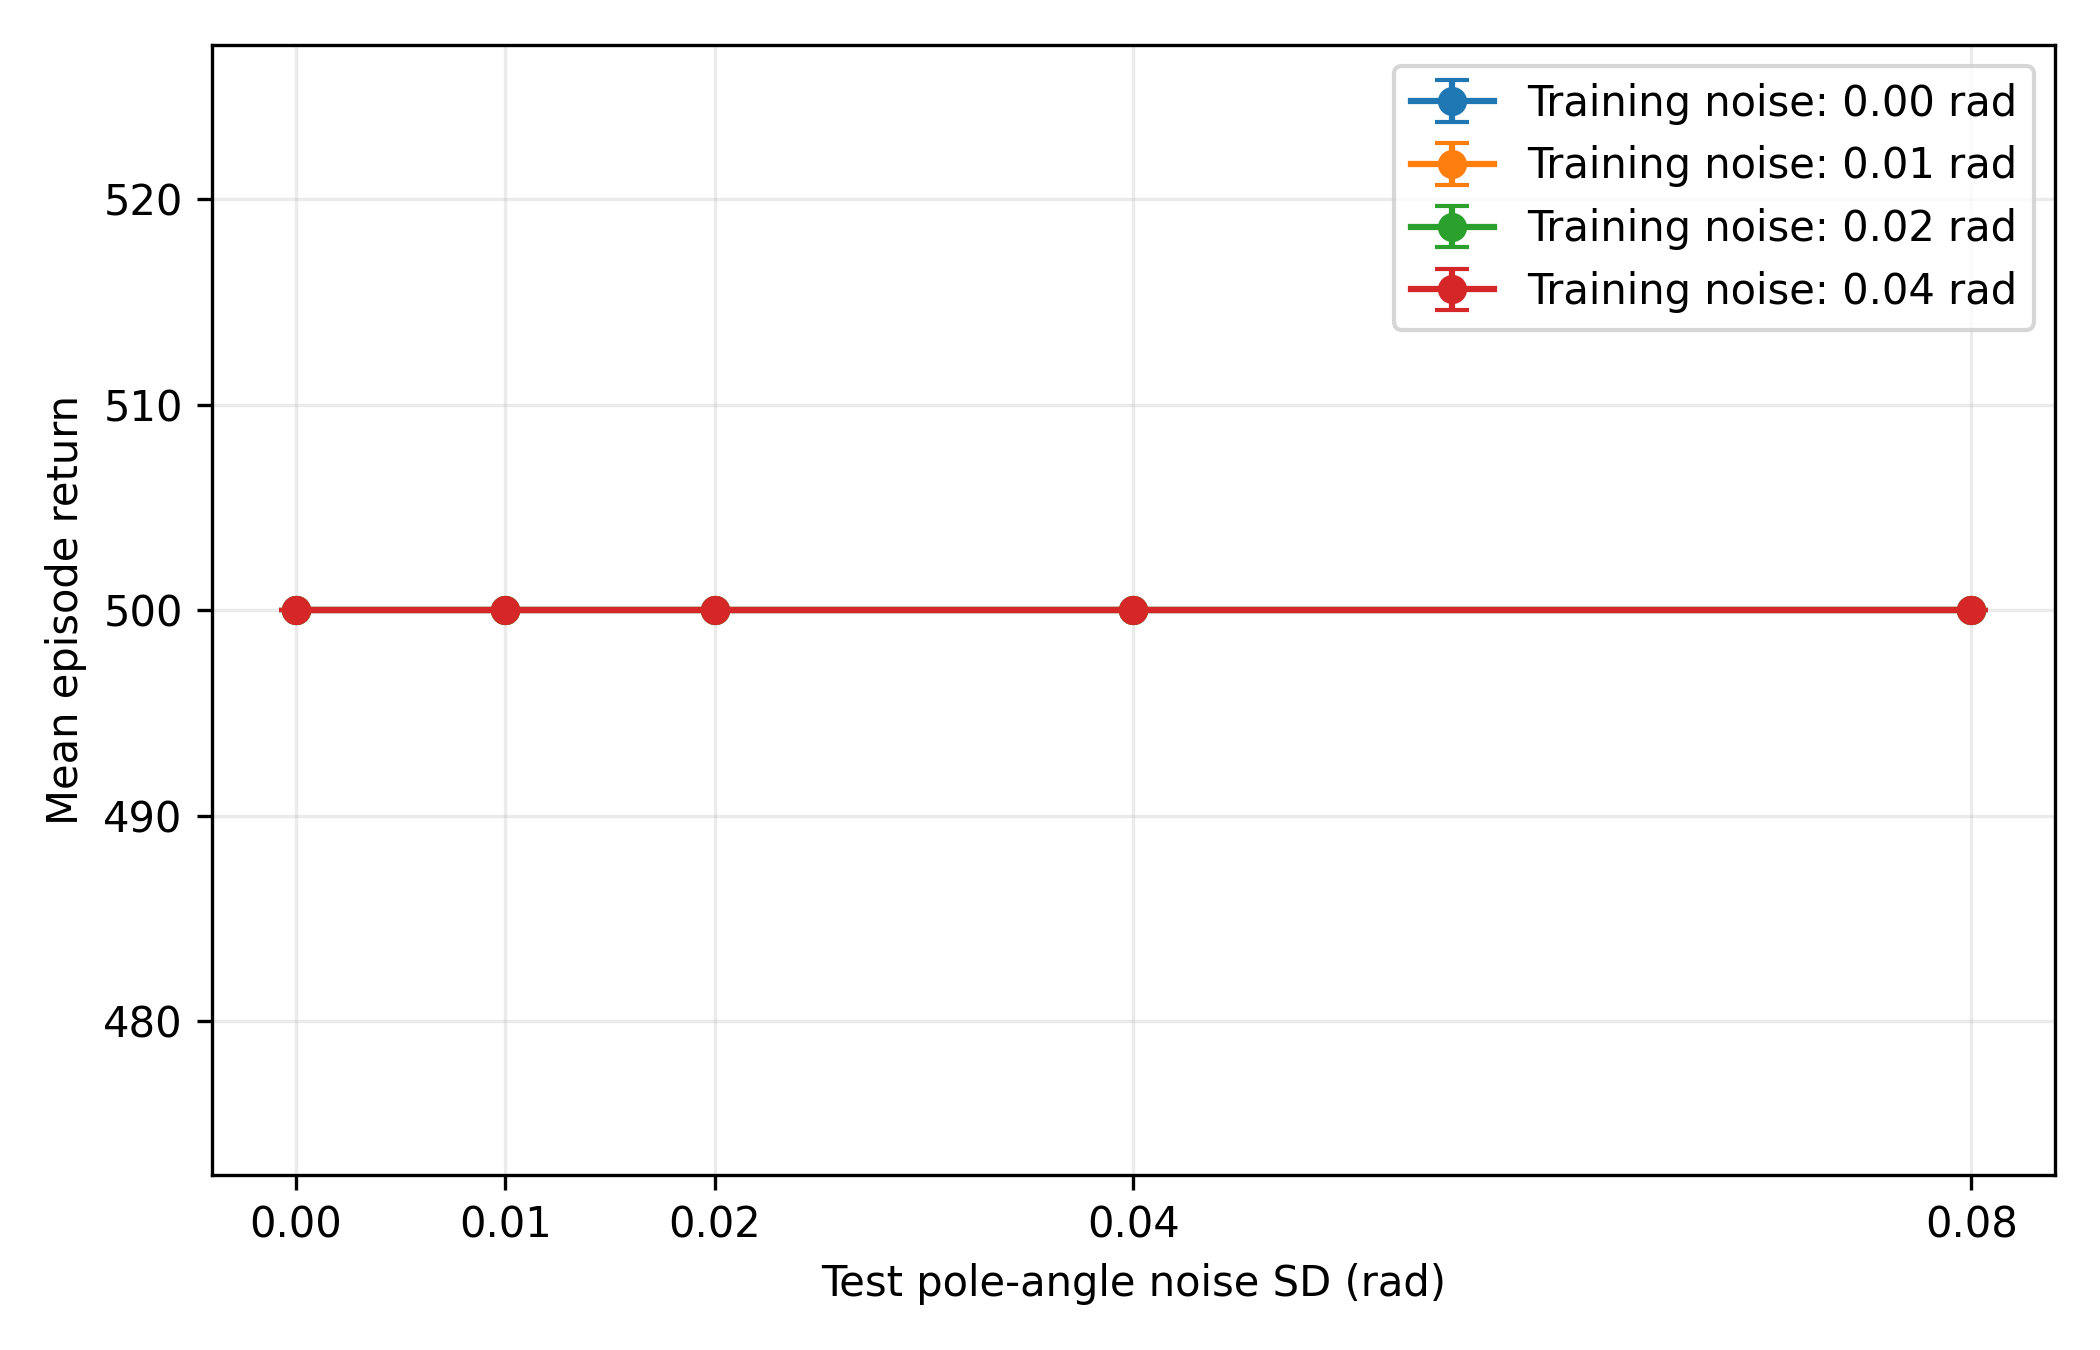

In [ ]:
# ============================================================
# Step 7: Display saved evaluation tables and the robustness figure
# Report use: Review the results from this run in one place.
# ============================================================

from io import BytesIO
from pathlib import Path
from zipfile import ZipFile

import pandas as pd
from IPython.display import Image, Markdown, display

tables = (
    ("Evaluation summary", "summary.csv"),
    ("Mean return for each training seed", "seed_means.csv"),
    ("All 1,800 evaluation episodes", "episode_returns.csv"),
)

required_files = [filename for _, filename in tables] + ["robustness.png"]

def show_results(read_file):
    for title, filename in tables:
        display(Markdown(f"### {title}"))
        table = pd.read_csv(BytesIO(read_file(filename)))

        if filename == "episode_returns.csv":
            print(table.to_string(index=False))
        else:
            display(table)

    display(Markdown("### Robustness figure"))
    display(Image(data=read_file("robustness.png")))

saved_dir = globals().get("evaluation_dir")
saved_dir = Path(saved_dir) if saved_dir is not None else None

if saved_dir is not None and all(
    (saved_dir / filename).is_file() for filename in required_files
):
    show_results(lambda filename: (saved_dir / filename).read_bytes())
else:
    from google.colab import files

    print("Upload PPO_CartPole_20261121_191809_887209.zip.")
    uploaded = files.upload()

    if len(uploaded) != 1:
        raise ValueError("Please upload exactly one results ZIP.")

    with ZipFile(BytesIO(next(iter(uploaded.values())))) as archive:
        missing = [
            filename for filename in required_files
            if f"evaluation/{filename}" not in archive.namelist()
        ]
        if missing:
            raise ValueError(f"Missing files in the results ZIP: {', '.join(missing)}")

        show_results(lambda filename: archive.read(f"evaluation/{filename}"))

第 1 次：选择原始 PPO_CartPole_…(2).zip


Saving PPO_CartPole_20261121_191809_887209.zip to PPO_CartPole_20261121_191809_887209 (1).zip
第 2 次：选择 PPO_Noise_Transfer.zip


Saving PPO_Noise_Transfer.zip to PPO_Noise_Transfer (1).zip

Table 1. Baseline PPO evaluation without added noise


,Episodes,Mean,Minimum,Maximum
Training seed,,,,
1,30,500.0,500.0,500.0
2,30,500.0,500.0,500.0
3,30,500.0,500.0,500.0



Figure 1. PPO performance under two observation-noise patterns


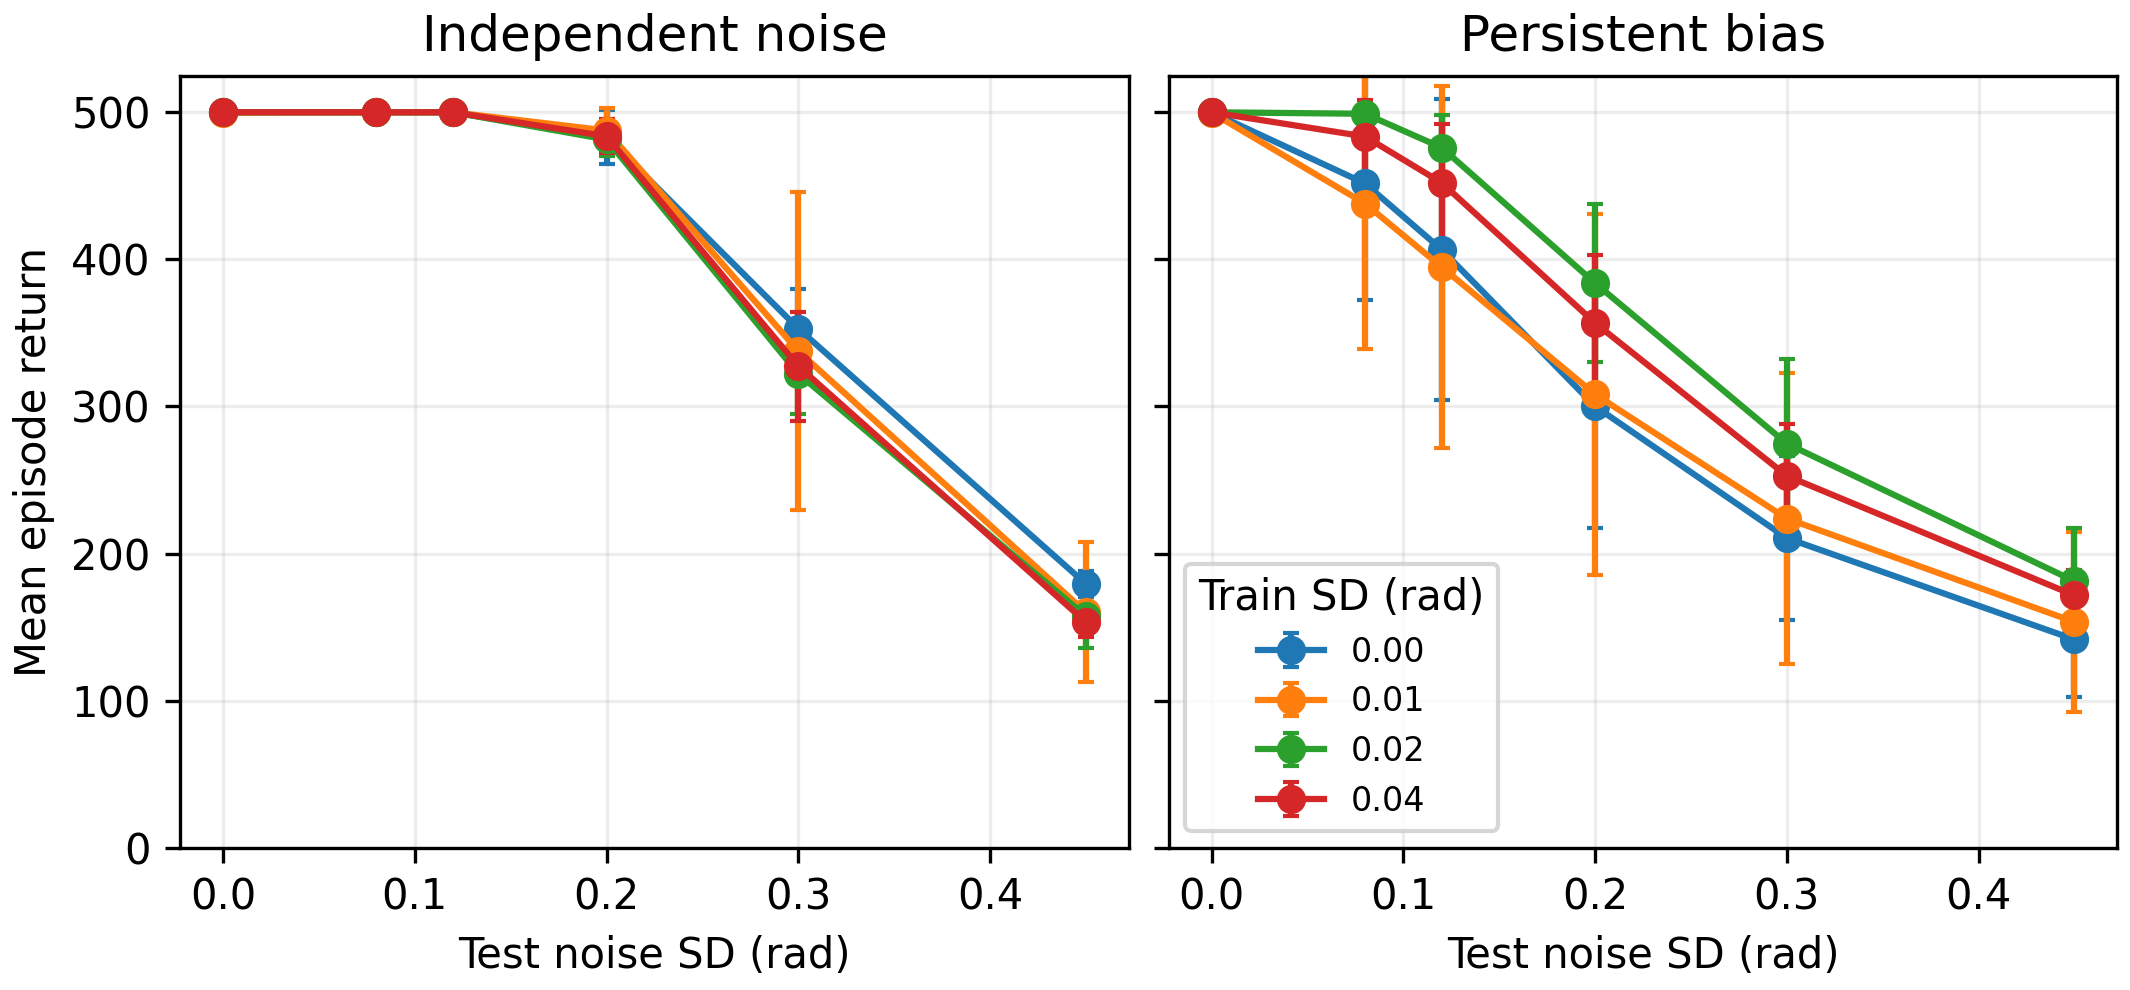


Figure 2. Paired differences from the baseline by training seed


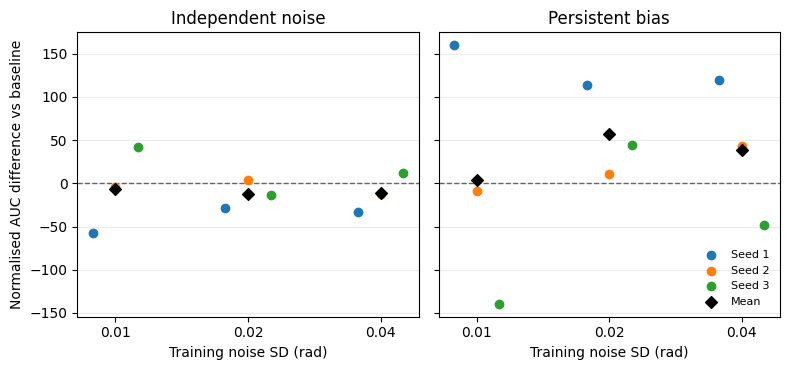

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from io import BytesIO
from pathlib import Path
from zipfile import BadZipFile, ZipFile
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import files
from IPython.display import display

def load_zip(prompt, required):
    while True:
        print(prompt, flush=True)
        uploaded = files.upload()
        if not uploaded:
            raise RuntimeError("上传已取消。重新运行这一格即可。")

        for content in uploaded.values():
            try:
                archive = ZipFile(BytesIO(content))
            except BadZipFile:
                continue

            if set(required).issubset(archive.namelist()):
                return archive
            archive.close()

        print("选错文件了，请按提示重新选对应的 ZIP。", flush=True)

with load_zip(
    "第 1 次：选择原始 PPO_CartPole_…(2).zip",
    ["evaluation/episode_returns.csv"],
) as original:
    episodes = pd.read_csv(BytesIO(original.read("evaluation/episode_returns.csv")))

with load_zip(
    "第 2 次：选择 PPO_Noise_Transfer.zip",
    ["results/paired_auc.csv", "results/noise_transfer.png",
     "results/noise_transfer.pdf"],
) as transfer:
    paired = pd.read_csv(BytesIO(transfer.read("results/paired_auc.csv")))
    figure1 = {
        ext: transfer.read(f"results/noise_transfer.{ext}")
        for ext in ("png", "pdf")
    }

out = Path("/content/ppo_report_figures")
out.mkdir(exist_ok=True)

# Table 1: Clean baseline, evaluated without added noise.
clean = episodes.loc[
    episodes["train_noise_std_rad"].eq(0)
    & episodes["test_noise_std_rad"].eq(0)
]
baseline = clean.groupby("training_seed")["episode_return"].agg(
    Episodes="size", Mean="mean", Minimum="min", Maximum="max"
)
baseline.index.name = "Training seed"
baseline.to_csv(out / "table1_baseline_reproduction.csv")

print("\nTable 1. Baseline PPO evaluation without added noise")
display(baseline)

# Figure 1: Return curves under independent noise and persistent bias.
for ext, data in figure1.items():
    (out / f"figure1_noise_transfer.{ext}").write_bytes(data)

print("\nFigure 1. PPO performance under two observation-noise patterns")
from IPython.display import Image
display(Image(filename=str(out / "figure1_noise_transfer.png")))

# Figure 2: Paired AUC differences relative to the same-seed baseline.
paired = paired.loc[paired["train_sd"].gt(0)]
groups = sorted(paired["train_sd"].unique())
seeds = sorted(paired["train_seed"].unique())
positions = np.arange(len(groups))
offsets = np.linspace(-0.17, 0.17, len(seeds))

fig, axes = plt.subplots(1, 2, figsize=(8, 3.8), sharey=True)

for ax, mode, title in zip(
    axes,
    ["iid", "constant_bias"],
    ["Independent noise", "Persistent bias"],
):
    data = paired.loc[paired["mode"].eq(mode)]
    ax.axhline(0, color="0.4", linestyle="--", linewidth=1)

    for seed, offset in zip(seeds, offsets):
        values = (
            data.loc[data["train_seed"].eq(seed)]
            .set_index("train_sd")["delta_vs_baseline"]
            .reindex(groups)
        )
        ax.scatter(positions + offset, values, label=f"Seed {seed}", zorder=3)

    means = data.groupby("train_sd")["delta_vs_baseline"].mean().reindex(groups)
    ax.scatter(positions, means, marker="D", color="black", label="Mean", zorder=4)
    ax.set_xticks(positions, [f"{x:.2f}" for x in groups])
    ax.set(title=title, xlabel="Training noise SD (rad)")
    ax.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Normalised AUC difference vs baseline")
axes[1].legend(fontsize=8, frameon=False)
fig.tight_layout()

for ext in ("png", "pdf"):
    fig.savefig(out / f"figure2_paired_differences.{ext}", dpi=300)

print("\nFigure 2. Paired differences from the baseline by training seed")
plt.show()
plt.close(fig)

archive_path = shutil.make_archive(
    "/content/PPO_Report_Figures", "zip", root_dir=out
)
files.download(archive_path)

Preparing the pinned CleanRL source and dependencies...
Training seed 1 of 3...
Seed 1 complete: 1,605 episodes recorded.
Training seed 2 of 3...
Seed 2 complete: 1,488 episodes recorded.
Training seed 3 of 3...
Seed 3 complete: 1,459 episodes recorded.


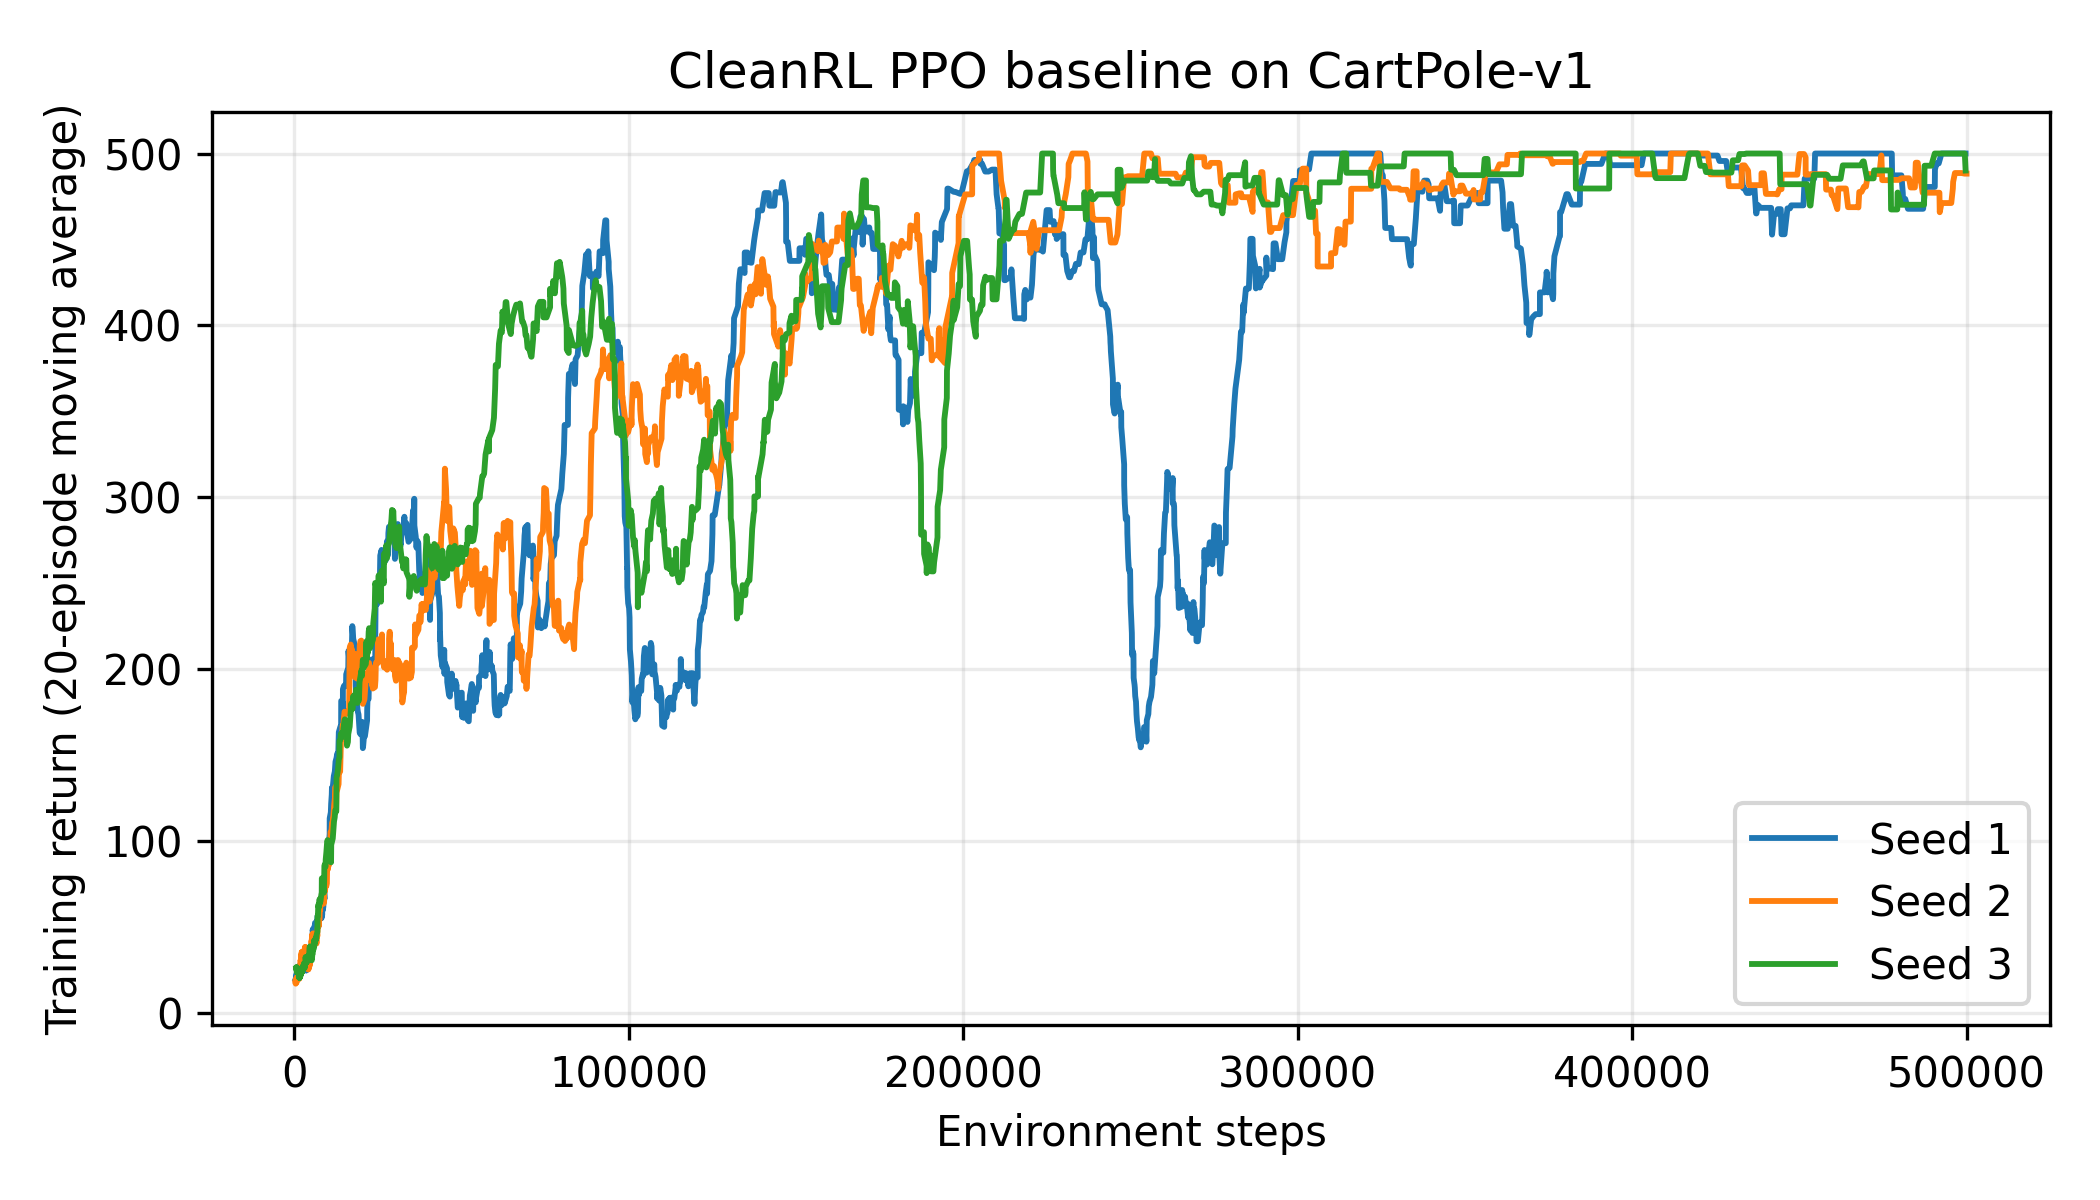

BASELINE REPRODUCTION RUNS COMPLETE
Results: /content/PPO_CartPole_Report/clean_baseline_reproduction/baseline_yd9w7rhc


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# ============================================================
# Supplement: Reproduce the clean CartPole PPO learning curves.
# Report use: Compare training progress with the CleanRL benchmark.
# ============================================================

import csv
import json
import shutil
import subprocess
import sys
from collections import deque
from importlib.metadata import version
from pathlib import Path
from tempfile import mkdtemp

from google.colab import files

commit = "fe8d8a03c41a7ef5b523e2e354bd01c363e786bb"
root = Path("/content/PPO_CartPole_Report/clean_baseline_reproduction")
root.mkdir(parents=True, exist_ok=True)
out = Path(mkdtemp(prefix="baseline_", dir=root))
source = out / "source"
source.mkdir()

def run(args, **kwargs):
    return subprocess.run(args, check=True, **kwargs)

def git(*args):
    return run(
        ["git", "-C", str(source), *args], capture_output=True, text=True
    ).stdout.strip()

print("Preparing the pinned CleanRL source and dependencies...", flush=True)
git("init", "-q")
git("fetch", "--depth", "1", "https://github.com/vwxyzjn/cleanrl.git", commit)
git("checkout", "--detach", "FETCH_HEAD")

script = source / "cleanrl" / "ppo.py"
if git("rev-parse", "HEAD") != commit or not script.is_file():
    raise RuntimeError("Could not verify the pinned CleanRL PPO script.")

run([
    sys.executable, "-m", "pip", "install", "-q",
    "gymnasium==1.4.0", "tensorboard", "tyro",
])

launcher = out / "launch_logged_ppo.py"
launcher.write_text(r'''
import csv
import runpy
import sys
import types
from pathlib import Path

script = Path(sys.argv[1]).resolve()
csv_path = Path(sys.argv[2]).resolve()
sys.argv = [str(script), *sys.argv[3:]]
sys.path.insert(0, str(script.parent.parent))
sys.modules["tensorboard.compat.notf"] = types.ModuleType("tensorboard.compat.notf")

import gymnasium as gym

make_env = gym.make
vector_step = gym.vector.SyncVectorEnv.step
pending = []
global_step = 0

class EpisodeLogger(gym.Wrapper):
    def reset(self, **kwargs):
        self.reward_sum = 0.0
        self.length = 0
        return self.env.reset(**kwargs)

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        self.reward_sum += float(reward)
        self.length += 1
        if terminated or truncated:
            pending.append((self.reward_sum, self.length))
        return obs, reward, terminated, truncated, info

def logged_make(*args, **kwargs):
    return EpisodeLogger(make_env(*args, **kwargs))

with csv_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["global_step", "episode_return", "episode_length"])

    def logged_step(env, actions):
        global global_step
        result = vector_step(env, actions)
        global_step += env.num_envs
        if pending:
            writer.writerows((global_step, reward, length) for reward, length in pending)
            pending.clear()
            file.flush()
        return result

    gym.make = logged_make
    gym.vector.SyncVectorEnv.step = logged_step
    runpy.run_path(str(script), run_name="__main__")
''', encoding="utf-8")

seeds = [1, 2, 3]
window = 20
args = [
    "--env-id", "CartPole-v1",
    "--total-timesteps", "500224",
    "--num-envs", "4",
    "--num-steps", "128",
    "--no-cuda",
]

(out / "run_config.json").write_text(json.dumps({
    "cleanrl_commit": commit,
    "python": sys.version,
    "packages": {
        name: version(name)
        for name in ("gymnasium", "torch", "numpy", "tensorboard", "tyro", "matplotlib")
    },
    "seeds": seeds,
    "training_observation_noise_sd_rad": 0.0,
    "ppo_arguments_excluding_seed": args,
    "moving_average_episodes": window,
}, indent=2), encoding="utf-8")

for seed in seeds:
    folder = out / f"seed_{seed}"
    folder.mkdir()
    csv_path = folder / "training_returns.csv"
    log_path = folder / "training.log"
    print(f"Training seed {seed} of {len(seeds)}...", flush=True)

    try:
        with log_path.open("w", encoding="utf-8") as log:
            run([
                sys.executable, "-u", str(launcher), str(script),
                str(csv_path), *args, "--seed", str(seed),
            ], cwd=folder, stdout=log, stderr=subprocess.STDOUT)
    except subprocess.CalledProcessError:
        print("\n".join(log_path.read_text(errors="replace").splitlines()[-20:]))
        raise

    with csv_path.open(newline="", encoding="utf-8") as file:
        episodes = sum(1 for _ in csv.DictReader(file))
    if episodes < window:
        raise RuntimeError(f"Seed {seed}: only {episodes} episodes were recorded.")
    print(f"Seed {seed} complete: {episodes:,} episodes recorded.", flush=True)

# Plot in a fresh Python process so it uses the installed packages.
plot_code = r'''
import csv
import sys
from collections import deque
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

out = Path(sys.argv[1])
window = int(sys.argv[2])
fig, ax = plt.subplots(figsize=(7, 4))

for seed in map(int, sys.argv[3:]):
    recent = deque(maxlen=window)
    steps, means = [], []
    path = out / f"seed_{seed}" / "training_returns.csv"
    with path.open(newline="", encoding="utf-8") as file:
        for row in csv.DictReader(file):
            recent.append(float(row["episode_return"]))
            if len(recent) == window:
                steps.append(int(row["global_step"]))
                means.append(sum(recent) / window)
    ax.plot(steps, means, label=f"Seed {seed}", linewidth=1.4)

ax.set(
    title="CleanRL PPO baseline on CartPole-v1",
    xlabel="Environment steps",
    ylabel=f"Training return ({window}-episode moving average)",
)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(out / f"clean_baseline_learning_curves.{ext}", dpi=300)
'''
plot_script = out / "plot_learning_curves.py"
plot_script.write_text(plot_code, encoding="utf-8")
run([sys.executable, str(plot_script), str(out), str(window), *map(str, seeds)])

from IPython.display import Image, display
from zipfile import ZIP_DEFLATED, ZipFile

display(Image(filename=str(out / "clean_baseline_learning_curves.png")))

archive = out.with_suffix(".zip")
with ZipFile(archive, "w", ZIP_DEFLATED) as bundle:
    for path in out.rglob("*"):
        relative = path.relative_to(out)
        if path.is_file() and ".git" not in relative.parts:£
            bundle.write(path, relative)

print("BASELINE REPRODUCTION RUNS COMPLETE")
print("Results:", out)
files.download(str(archive))